# Quickstart: Norway field production (Sodir)

`ogprod` downloads public well- and field-level production data and normalizes
it into one canonical DataFrame. This notebook walks the whole loop on the
smallest source: Norway's Sodir `field_production_monthly` table — every field
on the Norwegian shelf, monthly, back to 1971, in a single ~2 MB CSV.

Run it from the `notebooks/` directory with the notebook dependencies:

```sh
uv run --group notebooks jupyter lab
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ogprod

# Categorical palette in fixed slot order (colorblind-safe adjacency)
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "figure.figsize": (9, 4),
    "font.size": 11,
})

DATA = Path("../data")
DATA.mkdir(exist_ok=True)

In [2]:
ogprod.available()

['anp', 'argentina', 'sodir']

## Fetch and load

`fetch` downloads the raw file(s) as published; `load` parses them into the
canonical schema. The two are separate on purpose — `load` also accepts files
you downloaded by hand.

In [3]:
paths = ogprod.fetch("sodir", DATA)
frame = ogprod.load("sodir", paths[0])
frame.head()

,source,entity_type,entity_id,entity_name,field,basin,region,operator,period,product,volume
0,sodir,field,17196400,16/1-12 Troldhaugen,16/1-12 Troldhaugen,<NA>,<NA>,<NA>,2021-08-01,oil,6530.0
1,sodir,field,17196400,16/1-12 Troldhaugen,16/1-12 Troldhaugen,<NA>,<NA>,<NA>,2021-09-01,oil,25730.0
2,sodir,field,17196400,16/1-12 Troldhaugen,16/1-12 Troldhaugen,<NA>,<NA>,<NA>,2021-10-01,oil,11720.0
3,sodir,field,17196400,16/1-12 Troldhaugen,16/1-12 Troldhaugen,<NA>,<NA>,<NA>,2021-11-01,oil,12980.0
4,sodir,field,17196400,16/1-12 Troldhaugen,16/1-12 Troldhaugen,<NA>,<NA>,<NA>,2021-12-01,oil,4610.0


The canonical frame is long-format: one row per `(entity, month, product)`,
volumes **always in m³**. Norway reports five products:

In [4]:
frame.groupby("product")["volume"].sum().map("{:.3g} m³".format)

product
condensate    1.28e+08 m³
gas           3.31e+12 m³
ngl           5.05e+08 m³
oil           5.08e+09 m³
water         4.33e+09 m³
Name: volume, dtype: str

## Oil peaked around 2001 — gas has led since

Oil and gas volumes differ by two orders of magnitude, so they get two panels
with one axis each (never a dual-axis chart).

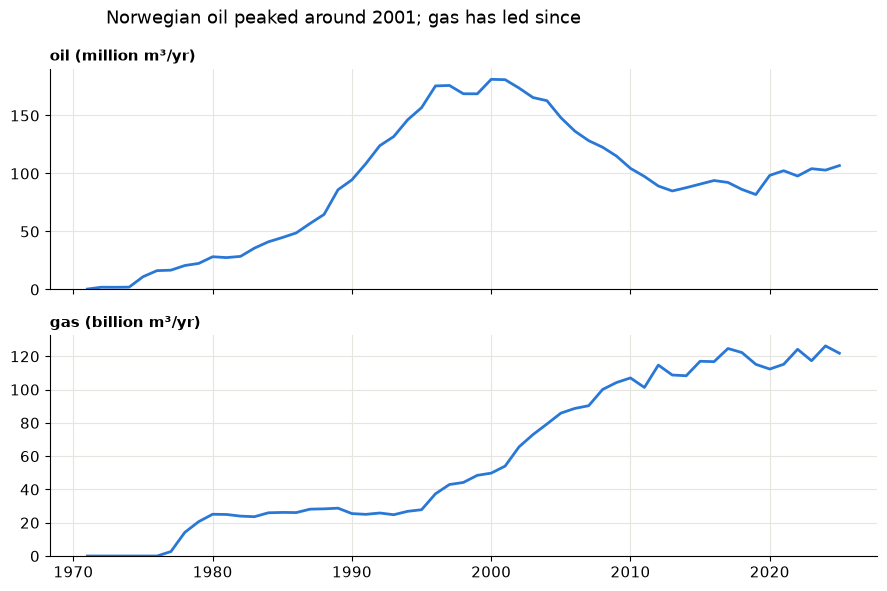

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, product, unit, scale in (
    (axes[0], "oil", "million m³/yr", 1e6),
    (axes[1], "gas", "billion m³/yr", 1e9),
):
    series = frame[frame["product"] == product]
    yearly = series.groupby(series["period"].dt.year)["volume"].sum() / scale
    yearly = yearly.iloc[:-1]  # drop the partial current year
    ax.plot(yearly.index, yearly.values)
    ax.set_title(f"{product} ({unit})", fontsize=11)
    ax.set_ylim(bottom=0)
fig.suptitle("Norwegian oil peaked around 2001; gas has led since", x=0.125, ha="left")
fig.tight_layout()

## A handful of giant fields dominate

`entity_id` is the stable Sodir NPDID; `entity_name` the field name. The
legend lists the series in slot order; every line has run down to near zero,
so end-of-line labels would collide.

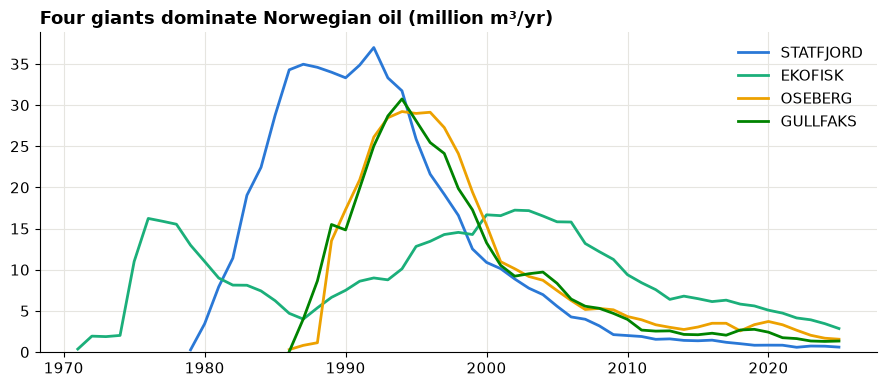

In [6]:
oil = frame[frame["product"] == "oil"]
top4 = oil.groupby("entity_name")["volume"].sum().nlargest(4).index

fig, ax = plt.subplots()
for name in top4:
    series = oil[oil["entity_name"] == name]
    yearly = (series.groupby(series["period"].dt.year)["volume"].sum() / 1e6).iloc[:-1]
    ax.plot(yearly.index, yearly.values, label=name)
ax.set_ylim(bottom=0)
ax.set_title("Four giants dominate Norwegian oil (million m³/yr)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()

## Units on demand

Everything is stored in m³; convert at the edge when you want oilfield units.

In [7]:
latest = frame[frame["period"] == frame["period"].max()]
oil_m3 = latest[latest["product"] == "oil"]["volume"].sum()
days = latest["period"].iloc[0].days_in_month
print(f"{latest['period'].iloc[0]:%B %Y}: "
      f"{ogprod.convert(oil_m3, 'm3', 'bbl') / days / 1e6:.2f} million bbl/d of oil")

April 2026: 1.95 million bbl/d of oil
